# LiteIDS (8-class) — Phase 3: Research Implementation and Experimental Evaluation


## 1. Setup and configuration

In [1]:
%pip install -q lightgbm
import os, sys, time, json, math, copy, random, shutil, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
import joblib, psutil, lightgbm as lgb
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef,
    precision_recall_fscore_support, average_precision_score, roc_auc_score, roc_curve)
warnings.filterwarnings('ignore')


from google.colab import drive; drive.mount('/content/drive'); os.chdir('/content/drive/MyDrive/Colab Notebooks')

# ---------------- configuration ----------------
QUICK     = False                     # True = tiny smoke test
USE_NN    = True                       # False = classical baselines only
PROTOCOLS = ['main']                   # single pooled 70/15/15 protocol, see Section 0
SEEDS     = [0]                  # use list(range(10)) for the full Phase 2 protocol
ABL_SEEDS = [0]
EPOCHS, PATIENCE, BATCH, LR = 40, 8, 1024, 3e-3
LOSS_POWER = .25                       # class-weight strength (0 = plain CE, 1 = fully balanced); accuracy-oriented default
SELECT = 'accuracy'                    # best epoch chosen on validation 'accuracy' (or 'macro_f1')
if QUICK: SEEDS, ABL_SEEDS, EPOCHS, PATIENCE = [0], [0], 2, 2

try:
    from google.colab import drive
    drive.mount('/content/drive'); ROOT = Path('/content/drive/MyDrive')
except Exception:
    ROOT = Path('.'); print('Not on Colab: saving to the local folder instead.')
OUT = ROOT / 'LiteIDS_8Class_Phase3_Final_Results'; FIG, TAB, MOD = OUT/'figures', OUT/'tables', OUT/'models'
for p in (FIG, TAB, MOD): p.mkdir(parents=True, exist_ok=True)
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEV == 'cuda'
sns.set_theme(style='whitegrid', context='notebook')
print('device:', DEV, '| outputs ->', OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | outputs -> /content/drive/MyDrive/LiteIDS_8Class_Phase3_Final_Results


In [2]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG/f'{name}.png', dpi=200, bbox_inches='tight'); plt.show()

def savetab(df, name, index=True):
    df.to_csv(TAB/f'{name}.csv', index=index); return df

def hardware():
    cpu = platform.processor() or platform.machine()
    try: cpu = [l.split(':')[1].strip() for l in open('/proc/cpuinfo') if 'model name' in l][0]
    except Exception: pass
    return dict(cpu=cpu, cpu_count=os.cpu_count(), ram_gb=round(psutil.virtual_memory().total/1e9, 1),
                gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none',
                torch=torch.__version__, python=platform.python_version())
HW = hardware(); print(HW)
json.dump(dict(HW=HW, QUICK=QUICK, PROTOCOLS=PROTOCOLS, SEEDS=SEEDS, ABL_SEEDS=ABL_SEEDS, EPOCHS=EPOCHS,
               PATIENCE=PATIENCE, BATCH=BATCH, LR=LR), open(OUT/'config.json', 'w'), indent=2)

{'cpu': 'Intel(R) Xeon(R) CPU @ 2.00GHz', 'cpu_count': 2, 'ram_gb': 13.6, 'gpu': 'Tesla T4', 'torch': '2.14.1+cu130', 'python': '3.13.16'}


## 2. Dataset and preprocessing
**UNSW-NB15** partitioned files (175,341 + 82,332 = 257,673 records), 42 features; the original 10 classes (Normal + 9 attack families) are merged to **8 classes** (Section 0), pooled and re-split 70/15/15.
Pipeline (all statistics fitted on the **training split only**): drop `id`; repair infinite / missing values; categorical fields (`proto`, `service`, `state`) → integer codes from a vocabulary fixed on train (index 0 = unseen); `log1p` on heavy-tailed non-negative features (skew > 5); standardise with train mean/std; clip to ±10. **No oversampling** in the main pipeline: imbalance is handled inside the loss (softened class weights).

8-class taxonomy; merged: {'DoS': 'DoS+Exploits+Fuzzers', 'Exploits': 'DoS+Exploits+Fuzzers', 'Fuzzers': 'DoS+Exploits+Fuzzers'}
train (175341, 45) | test (82332, 45) | 39 numeric + 3 categorical features


,train_file,test_file,pooled
attack_cat,,,
Analysis,2000,677,2677
Backdoor,1746,583,2329
DoS+Exploits+Fuzzers,63841,21283,85124
Generic,40000,18871,58871
Normal,56000,37000,93000
Reconnaissance,10491,3496,13987
Shellcode,1133,378,1511
Worms,130,44,174


exact duplicate records in pooled data: 98558 (38.2%)


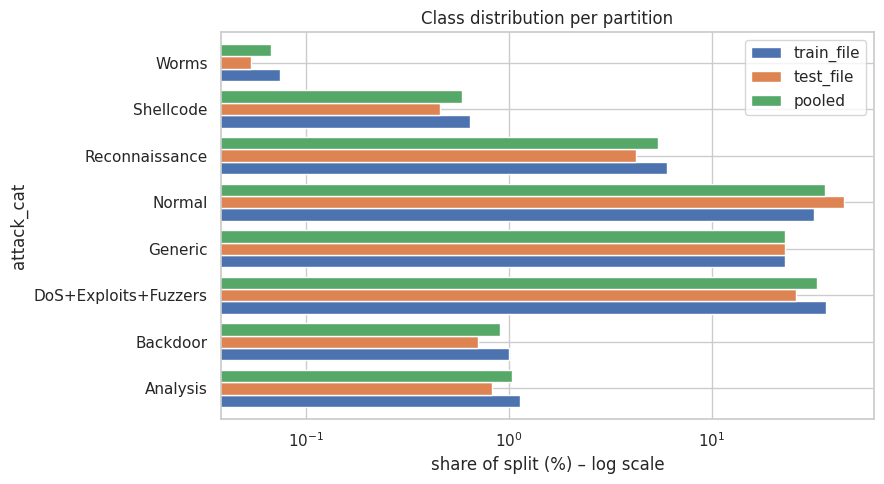

In [3]:
def find(name):
    cands = [Path('.') / name, Path('/content') / name, ROOT / name] + list(ROOT.glob(f'*/{name}')) + list(Path('.').rglob(name))
    for p in cands:
        if p.exists(): return p
    raise FileNotFoundError(f'{name} not found (looked next to the notebook, /content, MyDrive and its sub-folders)')

raw_tr = pd.read_csv(find('UNSW_NB15_training-set.csv'))
raw_te = pd.read_csv(find('UNSW_NB15_testing-set.csv'))
MERGE8 = {'DoS': 'DoS+Exploits+Fuzzers', 'Exploits': 'DoS+Exploits+Fuzzers', 'Fuzzers': 'DoS+Exploits+Fuzzers'}
for _df in (raw_tr, raw_te): _df['attack_cat'] = _df['attack_cat'].astype(str).str.strip().replace({'Backdoors': 'Backdoor'}).replace(MERGE8)
print('8-class taxonomy; merged:', MERGE8)
CLASSES = sorted(raw_tr.attack_cat.unique()); C = len(CLASSES)
CLS2ID = {c: i for i, c in enumerate(CLASSES)}; NORMAL = CLS2ID['Normal']
CAT_COLS = ['proto', 'service', 'state']
NUM_COLS = [c for c in raw_tr.columns if c not in CAT_COLS + ['id', 'attack_cat', 'label']]
print('train', raw_tr.shape, '| test', raw_te.shape, '|', len(NUM_COLS), 'numeric +', len(CAT_COLS), 'categorical features')

pooled = pd.concat([raw_tr.drop(columns='id'), raw_te.drop(columns='id')], ignore_index=True)
dist = pd.DataFrame({'train_file': raw_tr.attack_cat.value_counts(), 'test_file': raw_te.attack_cat.value_counts(),
                     'pooled': pooled.attack_cat.value_counts()}).loc[CLASSES]
savetab(dist, 'class_distribution'); display(dist)
print('exact duplicate records in pooled data:', pooled.duplicated().sum(), f'({100*pooled.duplicated().mean():.1f}%)')

pct = dist.div(dist.sum()) * 100
ax = pct[['train_file', 'test_file', 'pooled']].plot.barh(figsize=(9, 5), width=.8)
ax.set_xscale('log'); ax.set_xlabel('share of split (%) – log scale'); ax.set_title('Class distribution per partition')
savefig('fig01_class_distribution')

In [4]:
class Prep:
    def fit(self, df):
        self.vocab = {c: {v: i+1 for i, v in enumerate(sorted(df[c].unique()))} for c in CAT_COLS}   # 0 = unseen
        x = df[NUM_COLS].astype('float64')
        self.log_cols = [c for c in NUM_COLS if x[c].min() >= 0 and x[c].skew() > 5]
        x[self.log_cols] = np.log1p(x[self.log_cols])
        self.mu, self.sd = x.mean(), x.std().replace(0, 1).fillna(1)
        return self
    def transform(self, df):
        x = df[NUM_COLS].astype('float64').copy()
        x[self.log_cols] = np.log1p(x[self.log_cols].clip(lower=0))
        x = ((x - self.mu) / self.sd).clip(-10, 10).fillna(0)
        xc = np.stack([df[c].map(self.vocab[c]).fillna(0).astype(int).values for c in CAT_COLS], 1)
        return x.values.astype('float32'), xc.astype('int64')

def build_tensors(D):
    D['t'] = {k: tuple(torch.as_tensor(a).to(DEV) for a in D[k]) for k in ('train', 'val', 'test')}

def make_protocol(name, seed):
    a = raw_tr.drop(columns='id'); b = raw_te.drop(columns='id')
    d = pd.concat([a, b], ignore_index=True)
    tr, rest = train_test_split(d, test_size=.30, stratify=d.attack_cat, random_state=seed)
    va, te = train_test_split(rest, test_size=.50, stratify=rest.attack_cat, random_state=seed)
    if QUICK: tr = tr.sample(frac=.15, random_state=seed)
    _h = lambda df: pd.util.hash_pandas_object(df.drop(columns=['attack_cat', 'label']), index=False).values
    leak = 100 * np.isin(_h(te), _h(tr)).mean()          # % of test rows with an exact feature copy in train
    prep = Prep().fit(tr)
    D = dict(name=name, seed=seed, prep=prep, vocab=[len(prep.vocab[c]) + 1 for c in CAT_COLS],
             n_num=len(NUM_COLS), num_cols=list(NUM_COLS), leak_pct=leak)
    for k, df in (('train', tr), ('val', va), ('test', te)):
        xn, xc = prep.transform(df); D[k] = (xn, xc, df.attack_cat.map(CLS2ID).values.astype('int64'))
    build_tensors(D); return D

_CACHE = {}
def get_protocol(name, seed):
    if (name, seed) not in _CACHE: _CACHE[(name, seed)] = make_protocol(name, seed)
    return _CACHE[(name, seed)]

setup = []
for p in PROTOCOLS:
    D = get_protocol(p, SEEDS[0])
    setup.append({'protocol': p, 'train': len(D['train'][2]), 'val': len(D['val'][2]), 'test': len(D['test'][2]),
                  'log1p features': len(D['prep'].log_cols), 'cat vocab sizes': D['vocab'],
                  'test rows with exact copy in train (%)': round(D['leak_pct'], 1)})
savetab(pd.DataFrame(setup), 'experimental_setup', index=False); display(pd.DataFrame(setup))
print('log-transformed features:', D['prep'].log_cols)

,protocol,train,val,test,log1p features,cat vocab sizes,test rows with exact copy in train (%)
0,main,180371,38651,38651,21,"[134, 14, 9]",44.5


log-transformed features: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'sload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'trans_depth', 'response_body_len', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports']


## 3. The proposed model: LiteIDS
* **Feature tokenizer** – each numeric feature *i* becomes a token `x_i · w_i + b_i` (learned vectors), each categorical feature a learned embedding, plus a `[CLS]` token. No image conversion.
* **1–3 lightweight pre-LN self-attention blocks** – few heads, width ≤ 128, feed-forward expansion 2 (not 4), optional squeeze-and-excitation gating.
* **Linear head** on the `[CLS]` token over the 8 classes; trained **directly in one stage** (AdamW + one-cycle schedule, softened class-weighted cross-entropy, early stopping on validation macro-F1).
Variants: `LiteIDS-S` (≈10k params), `LiteIDS` (main, ≈90k, the Phase 2 "≤100k" target), `LiteIDS-L` (≈0.5M, also used as the teacher in the teacher–student comparison).

In [5]:
class SE(nn.Module):
    def __init__(s, d, r=4):
        super().__init__(); h = max(d // r, 4)
        s.f = nn.Sequential(nn.Linear(d, h), nn.ReLU(), nn.Linear(h, d), nn.Sigmoid())
    def forward(s, x): return x * s.f(x.mean(1, keepdim=True))

class MHA(nn.Module):
    def __init__(s, d, h):
        super().__init__(); s.h = h; s.qkv = nn.Linear(d, 3*d); s.o = nn.Linear(d, d)
    def forward(s, x, ret=False):
        B, T, D = x.shape
        q, k, v = s.qkv(x).view(B, T, 3, s.h, D // s.h).permute(2, 0, 3, 1, 4)
        a = ((q @ k.transpose(-2, -1)) / math.sqrt(D // s.h)).softmax(-1)
        y = s.o((a @ v).transpose(1, 2).reshape(B, T, D))
        return (y, a) if ret else y

class TokenMix(nn.Module):            # attention-free replacement used in the ablation
    def __init__(s, T): super().__init__(); s.l = nn.Linear(T, T)
    def forward(s, x): return s.l(x.transpose(1, 2)).transpose(1, 2)

class Block(nn.Module):
    def __init__(s, d, h, ff=2, se=True, mix=False, T=None, drop=.1):
        super().__init__(); s.mix = mix
        s.n1, s.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        s.att = TokenMix(T) if mix else MHA(d, h)
        s.ff = nn.Sequential(nn.Linear(d, ff*d), nn.GELU(), nn.Dropout(drop), nn.Linear(ff*d, d))
        s.se = SE(d) if se else nn.Identity(); s.dr = nn.Dropout(drop)
    def forward(s, x, ret=False):
        a = None
        if ret and not s.mix: y, a = s.att(s.n1(x), True)
        else: y = s.att(s.n1(x))
        x = x + s.dr(y); x = x + s.dr(s.se(s.ff(s.n2(x))))
        return (x, a) if ret else x

class LiteIDS(nn.Module):
    def __init__(s, n_num, vocab, n_cls, d=64, h=4, L=2, ff=2, se=True, mix=False, drop=.1):
        super().__init__()
        s.w = nn.Parameter(torch.randn(n_num, d) * .02); s.b = nn.Parameter(torch.zeros(n_num, d))
        s.cat = nn.ModuleList([nn.Embedding(v, d) for v in vocab])
        for e in s.cat: nn.init.normal_(e.weight, std=.02)
        s.cls = nn.Parameter(torch.randn(1, 1, d) * .02)
        T = 1 + n_num + len(vocab)
        s.blocks = nn.ModuleList([Block(d, h, ff, se, mix, T, drop) for _ in range(L)])
        s.norm = nn.LayerNorm(d); s.head = nn.Linear(d, n_cls)
    def forward(s, xn, xc, ret=False):
        t = xn.unsqueeze(-1) * s.w + s.b
        c = torch.stack([e(xc[:, i]) for i, e in enumerate(s.cat)], 1)
        x = torch.cat([s.cls.expand(xn.size(0), -1, -1), t, c], 1); atts = []
        for bl in s.blocks:
            if ret: x, a = bl(x, True); atts.append(a)
            else: x = bl(x)
        out = s.head(s.norm(x[:, 0]))
        return (out, atts) if ret else out

## 4. Baselines
* **Classical:** Random Forest, LightGBM (strong tabular references – do we need deep attention at all?).
* **Small neural nets:** MLP, 1D-CNN, CNN-LSTM.
* **Literature models re-implemented in the style of** Paper 4 (multi-scale attention 1D-CNN with SE + residual), Paper 5 (CNN + SE + BiLSTM + tiny single-head Transformer, centralised) and Paper 7 (CNN-LSTM with attention pooling).
* **Teacher–student:** `LiteIDS-L` distilled into `LiteIDS` (cost counted as teacher + student).
All use the same splits, preprocessing, seeds, optimiser and early-stopping rule.

In [6]:
class Flat(nn.Module):
    """Shared input encoder for the non-token baselines: numeric vector + small categorical embeddings."""
    def __init__(s, n_num, vocab, edim=4):
        super().__init__(); s.emb = nn.ModuleList([nn.Embedding(v, edim) for v in vocab]); s.out = n_num + edim * len(vocab)
    def forward(s, xn, xc): return torch.cat([xn] + [e(xc[:, i]) for i, e in enumerate(s.emb)], 1)

class MLP(nn.Module):
    def __init__(s, n_num, vocab, n_cls):
        super().__init__(); s.f = Flat(n_num, vocab)
        s.net = nn.Sequential(nn.Linear(s.f.out, 256), nn.ReLU(), nn.Dropout(.2), nn.Linear(256, 128), nn.ReLU(), nn.Dropout(.2), nn.Linear(128, n_cls))
    def forward(s, xn, xc): return s.net(s.f(xn, xc))

class CNN1D(nn.Module):
    def __init__(s, n_num, vocab, n_cls):
        super().__init__(); s.f = Flat(n_num, vocab)
        s.c1 = nn.Conv1d(1, 32, 3, padding=1); s.b1 = nn.BatchNorm1d(32)
        s.c2 = nn.Conv1d(32, 64, 3, padding=1); s.b2 = nn.BatchNorm1d(64); s.fc = nn.Linear(128, n_cls)
    def forward(s, xn, xc):
        h = F.relu(s.b2(s.c2(F.relu(s.b1(s.c1(s.f(xn, xc).unsqueeze(1)))))))
        return s.fc(torch.cat([h.mean(2), h.amax(2)], 1))

class CNNLSTM(nn.Module):
    def __init__(s, n_num, vocab, n_cls):
        super().__init__(); s.f = Flat(n_num, vocab)
        s.c = nn.Conv1d(1, 32, 3, padding=1); s.lstm = nn.LSTM(32, 64, batch_first=True); s.fc = nn.Sequential(nn.Dropout(.2), nn.Linear(64, n_cls))
    def forward(s, xn, xc):
        h = F.max_pool1d(F.relu(s.c(s.f(xn, xc).unsqueeze(1))), 2); o, _ = s.lstm(h.transpose(1, 2))
        return s.fc(o[:, -1])

class AttnCNNLSTM(nn.Module):      # Paper 7 style
    def __init__(s, n_num, vocab, n_cls):
        super().__init__(); s.f = Flat(n_num, vocab)
        s.c = nn.Conv1d(1, 32, 3, padding=1); s.lstm = nn.LSTM(32, 64, batch_first=True)
        s.att = nn.Linear(64, 1); s.fc = nn.Sequential(nn.Dropout(.2), nn.Linear(64, n_cls))
    def forward(s, xn, xc):
        h = F.max_pool1d(F.relu(s.c(s.f(xn, xc).unsqueeze(1))), 2); o, _ = s.lstm(h.transpose(1, 2))
        return s.fc((s.att(o).softmax(1) * o).sum(1))

class MSAttnCNN(nn.Module):        # Paper 4 style
    def __init__(s, n_num, vocab, n_cls, ch=16):
        super().__init__(); s.f = Flat(n_num, vocab)
        s.br = nn.ModuleList([nn.Conv1d(1, ch, k, padding=k // 2) for k in (3, 7, 15, 31)])
        D = ch * 4; s.bn = nn.BatchNorm1d(D)
        s.se = nn.Sequential(nn.Linear(D, D // 4), nn.ReLU(), nn.Linear(D // 4, D), nn.Sigmoid())
        s.res = nn.Conv1d(1, D, 1); s.fc = nn.Sequential(nn.Linear(2 * D, 64), nn.ReLU(), nn.Dropout(.2), nn.Linear(64, n_cls))
    def forward(s, xn, xc):
        x = s.f(xn, xc).unsqueeze(1); h = F.relu(s.bn(torch.cat([b(x) for b in s.br], 1)))
        h = h * s.se(h.mean(2)).unsqueeze(2) + s.res(x)
        return s.fc(torch.cat([h.mean(2), h.amax(2)], 1))

class TinyFlow(nn.Module):         # Paper 5 style
    def __init__(s, n_num, vocab, n_cls):
        super().__init__(); s.f = Flat(n_num, vocab)
        s.c1 = nn.Conv1d(1, 16, 3, padding=1); s.c2 = nn.Conv1d(16, 32, 3, padding=1)
        s.se = nn.Sequential(nn.Linear(32, 8), nn.ReLU(), nn.Linear(8, 32), nn.Sigmoid())
        s.lstm = nn.LSTM(32, 16, batch_first=True, bidirectional=True)
        s.tr = nn.TransformerEncoderLayer(32, 1, 64, dropout=.1, batch_first=True); s.fc = nn.Linear(32, n_cls)
    def forward(s, xn, xc):
        h = F.relu(s.c2(F.relu(s.c1(s.f(xn, xc).unsqueeze(1))))); h = h * s.se(h.mean(2)).unsqueeze(2)
        h, _ = s.lstm(h.transpose(1, 2)); return s.fc(s.tr(h).mean(1))

def lite(**kw): return lambda D: LiteIDS(D['n_num'], D['vocab'], C, **kw)
def plain(cls): return lambda D: cls(D['n_num'], D['vocab'], C)
WCE = dict(loss='wce', power=LOSS_POWER)
NN_ZOO = {   # name -> (factory, training kwargs)
    'LiteIDS-S': (lite(d=32, h=2, L=1), WCE),
    'LiteIDS':   (lite(d=64, h=4, L=2), WCE),
    'LiteIDS-L': (lite(d=128, h=4, L=3), WCE),
    'MLP': (plain(MLP), WCE), 'CNN-1D': (plain(CNN1D), WCE), 'CNN-LSTM': (plain(CNNLSTM), WCE),
    'MSAttn-CNN (P4-style)': (plain(MSAttnCNN), WCE), 'TinyFlow (P5-style)': (plain(TinyFlow), WCE),
    'AttnCNN-LSTM (P7-style)': (plain(AttnCNNLSTM), WCE)}
CLASSICAL = ['RandomForest', 'LightGBM']
_D = get_protocol(PROTOCOLS[0], SEEDS[0])
for n, (f, _) in NN_ZOO.items(): print(f'{n:26s} {sum(p.numel() for p in f(_D).parameters()):>9,d} parameters')

LiteIDS-S                     16,976 parameters
LiteIDS                       86,952 parameters
LiteIDS-L                    453,992 parameters
MLP                           47,868 parameters
CNN-1D                         8,188 parameters
CNN-LSTM                      26,364 parameters
MSAttn-CNN (P4-style)         12,748 parameters
TinyFlow (P5-style)           18,020 parameters
AttnCNN-LSTM (P7-style)       26,429 parameters


## 5. Training, evaluation and efficiency-profiling utilities

In [7]:
def class_weights(y, power):
    cnt = np.bincount(y, minlength=C).clip(min=1).astype('float64'); w = (cnt.sum() / cnt) ** power
    return torch.tensor(w / ((w * cnt).sum() / cnt.sum()), dtype=torch.float32)

def focal(logits, y, w, gamma=2.):
    lp = F.log_softmax(logits, 1); ce = F.nll_loss(lp, y, weight=w, reduction='none')
    return ((1 - lp.gather(1, y[:, None]).squeeze(1).exp()) ** gamma * ce).mean()

def oversample_idx(y, seed, target=3000):             # training split only (ablation)
    rng = np.random.default_rng(seed); idx = [np.arange(len(y))]
    for c in range(C):
        ids = np.where(y == c)[0]
        if 0 < len(ids) < target: idx.append(rng.choice(ids, target - len(ids), replace=True))
    return np.concatenate(idx)

@torch.no_grad()
def predict_proba(model, xn, xc, bs=4096):
    model.eval(); out = []
    for i in range(0, len(xn), bs):
        with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
            o = model(xn[i:i+bs], xc[i:i+bs])
        out.append(F.softmax(o.float(), 1).cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def logits_all(model, xn, xc, bs=4096):
    model.eval(); return torch.cat([model(xn[i:i+bs], xc[i:i+bs]).float() for i in range(0, len(xn), bs)])

def train_model(factory, D, seed, loss='wce', power=.5, epochs=None, lr=None, teacher_logits=None,
                kd_alpha=.5, kd_T=3., oversample=False, wd=1e-2):
    epochs = epochs or EPOCHS; lr = lr or LR
    set_seed(seed); model = factory(D).to(DEV)
    xn, xc, y = D['t']['train']; vxn, vxc, vy = D['t']['val']; vy_np = D['val'][2]
    idx_all = oversample_idx(D['train'][2], seed) if oversample else np.arange(len(y))
    w = class_weights(D['train'][2], 0. if loss == 'ce' else power).to(DEV)
    n = len(idx_all); spe = math.ceil(n / BATCH)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * spe, pct_start=.2)
    scaler = (torch.amp.GradScaler('cuda', enabled=AMP) if hasattr(torch.amp, 'GradScaler') else torch.cuda.amp.GradScaler(enabled=AMP))
    best, best_state, best_ep, bad, hist = -1., None, 0, 0, []
    if DEV == 'cuda': torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.perf_counter()
    for ep in range(epochs):
        model.train(); perm = torch.as_tensor(np.random.permutation(idx_all), device=DEV); tl = torch.zeros((), device=DEV)
        for i in range(0, n, BATCH):
            b = perm[i:i+BATCH]
            with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
                out = model(xn[b], xc[b])
            out = out.float()
            l = focal(out, y[b], w) if loss == 'focal' else F.cross_entropy(out, y[b], weight=w)
            if teacher_logits is not None:
                kd = F.kl_div(F.log_softmax(out / kd_T, 1), F.softmax(teacher_logits[b] / kd_T, 1), reduction='batchmean') * kd_T ** 2
                l = (1 - kd_alpha) * l + kd_alpha * kd
            opt.zero_grad(set_to_none=True); scaler.scale(l).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.); scaler.step(opt); scaler.update(); sched.step()
            tl += l.detach() * len(b)
        vp = predict_proba(model, vxn, vxc).argmax(1); vf1 = f1_score(vy_np, vp, average='macro', labels=list(range(C)), zero_division=0); vacc = accuracy_score(vy_np, vp)
        hist.append(dict(epoch=ep + 1, train_loss=float(tl) / n, val_macro_f1=vf1, val_accuracy=vacc)); score = vacc if SELECT == 'accuracy' else vf1
        if score > best + 1e-4: best, best_ep, bad = score, ep, 0; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    if DEV == 'cuda': torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    model.load_state_dict(best_state)
    peak = torch.cuda.max_memory_allocated() / 1e6 if DEV == 'cuda' else psutil.Process().memory_info().rss / 1e6
    return model, hist, dict(train_time_s=dt, epochs_run=len(hist), epochs_to_best=best_ep + 1,
                             time_per_epoch_s=dt / len(hist), peak_train_mem_mb=peak)

def metrics(y, prob):
    p = prob.argmax(1)
    pr, rc, f1, sup = precision_recall_fscore_support(y, p, labels=list(range(C)), zero_division=0)
    ap = [average_precision_score(y == c, prob[:, c]) if (y == c).any() else np.nan for c in range(C)]
    bt, bp = y != NORMAL, p != NORMAL
    m = dict(accuracy=accuracy_score(y, p), binary_accuracy=accuracy_score(bt, bp), macro_f1=f1.mean(),
             weighted_f1=f1_score(y, p, average='weighted', zero_division=0), macro_precision=pr.mean(), macro_recall=rc.mean(),
             balanced_acc=balanced_accuracy_score(y, p), mcc=matthews_corrcoef(y, p), macro_pr_auc=np.nanmean(ap),
             false_alarm_rate=((~bt) & bp).sum() / max((~bt).sum(), 1), binary_f1=f1_score(bt, bp, zero_division=0))
    return m, dict(precision=pr, recall=rc, f1=f1, support=sup)

def full_proba(model, X):
    p = model.predict_proba(X); out = np.zeros((len(X), C), dtype='float32'); out[:, model.classes_.astype(int)] = p; return out

def fit_classical(name, D, seed):
    Xtr = np.hstack([D['train'][0], D['train'][1]])
    m = (RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=seed) if name == 'RandomForest' else
         lgb.LGBMClassifier(n_estimators=300, learning_rate=.05, num_leaves=63, subsample=.8, subsample_freq=1,
                            colsample_bytree=.8, random_state=seed, verbose=-1, n_jobs=-1))
    t = time.perf_counter(); m.fit(Xtr, D['train'][2]); return m, time.perf_counter() - t

# ---------- efficiency profiling (CPU, single thread, batch size 1) ----------
def _lat(fn, n, warm=20):
    for _ in range(warm): fn()
    ts = []
    for _ in range(n):
        t = time.perf_counter(); fn(); ts.append((time.perf_counter() - t) * 1e3)
    ts = np.array(ts); return ts.mean(), np.percentile(ts, 95), np.percentile(ts, 99)

def _disk(obj, torch_state=False):
    tmp = Path('_tmp_size.bin')
    if torch_state: torch.save(obj.state_dict(), tmp)
    else: joblib.dump(obj, tmp, compress=0)
    s = tmp.stat().st_size / 1e6; tmp.unlink(); return s

def profile_nn(model, D, n_lat=300, full=True):
    prev = torch.get_num_threads(); torch.set_num_threads(1)
    m = copy.deepcopy(model).cpu().eval()
    xn = torch.as_tensor(D['test'][0][:1024]); xc = torch.as_tensor(D['test'][1][:1024])
    row = dict(params=sum(p.numel() for p in m.parameters()))
    try:
        from torch.utils.flop_counter import FlopCounterMode
        with torch.no_grad(), FlopCounterMode(display=False) as fc: m(xn[:1], xc[:1])
        row['flops'] = fc.get_total_flops()
    except Exception: row['flops'] = np.nan
    if full:
        row['size_mb'] = _disk(m, True)
        with torch.no_grad():
            row['lat_mean_ms'], row['lat_p95_ms'], row['lat_p99_ms'] = _lat(lambda: m(xn[:1], xc[:1]), n_lat)
            r0 = psutil.Process().memory_info().rss; m(xn[:256], xc[:256])
            row['infer_rss_delta_mb'] = (psutil.Process().memory_info().rss - r0) / 1e6
            t = time.perf_counter()
            for _ in range(5): m(xn, xc)
            row['throughput_sps'] = 5 * len(xn) / (time.perf_counter() - t)
    torch.set_num_threads(prev); return row

def profile_sklearn(model, D, n_lat=200):
    model.set_params(n_jobs=1); X = np.hstack([D['test'][0], D['test'][1]])[:4096]
    nodes = (sum(e.tree_.node_count for e in model.estimators_) if hasattr(model, 'estimators_')
             else int(model.booster_.trees_to_dataframe().shape[0]))
    row = dict(params=nodes, flops=np.nan, size_mb=_disk(model))      # 'params' = total tree nodes for tree models
    row['lat_mean_ms'], row['lat_p95_ms'], row['lat_p99_ms'] = _lat(lambda: model.predict_proba(X[:1]), n_lat, 10)
    t = time.perf_counter(); model.predict_proba(X); row['throughput_sps'] = len(X) / (time.perf_counter() - t)
    row['infer_rss_delta_mb'] = np.nan; return row

## 6. Main experiment (E1, E3, E4)
For every protocol and seed: train every model on the training split, pick the best epoch on the validation split, report on the test split. Training cost (wall-clock, epochs to best, time/epoch, peak memory) is logged for every model, and the teacher–student route is charged for **teacher + student**.

In [8]:
RES_ROWS, PC_ROWS = [], []
HIST, PRED, PROB, YTRUE, STORE = {}, {}, {}, {}, {}
NAN = dict(epochs_run=np.nan, epochs_to_best=np.nan, time_per_epoch_s=np.nan, peak_train_mem_mb=np.nan)

def record(prot, name, seed, y, prob, cost):
    m, pc = metrics(y, prob); RES_ROWS.append(dict(protocol=prot, model=name, seed=seed, **m, **cost))
    for c in range(C):
        PC_ROWS.append(dict(protocol=prot, model=name, seed=seed, cls=CLASSES[c], **{k: v[c] for k, v in pc.items()}))
    if seed == SEEDS[0]: PRED[(prot, name)] = prob.argmax(1); PROB[(prot, name)] = prob; YTRUE[prot] = y
    print(f'  {name:26s} acc={m["accuracy"]:.4f}  bin_acc={m["binary_accuracy"]:.4f}  macroF1={m["macro_f1"]:.4f}  '
          f'train={cost["train_time_s"]:.0f}s')

T_START = time.time()
for prot in PROTOCOLS:
    for seed in SEEDS:
        print(f'=== protocol={prot} seed={seed} ===')
        D = get_protocol(prot, seed); yte = D['test'][2]
        for name in CLASSICAL:
            m, dt = fit_classical(name, D, seed)
            record(prot, name, seed, yte, full_proba(m, np.hstack([D['test'][0], D['test'][1]])), dict(train_time_s=dt, **NAN))
            if seed == SEEDS[0]: STORE[(prot, name)] = m
        if USE_NN:
            trained = {}
            for name, (factory, kw) in NN_ZOO.items():
                model, hist, cost = train_model(factory, D, seed, **kw)
                record(prot, name, seed, yte, predict_proba(model, *D['t']['test'][:2]), cost); trained[name] = (model, cost)
                if seed == SEEDS[0]: STORE[(prot, name)] = copy.deepcopy(model).cpu(); HIST[(prot, name)] = hist
            teacher, tcost = trained['LiteIDS-L']
            tl = logits_all(teacher, D['t']['train'][0], D['t']['train'][1])
            model, hist, cost = train_model(NN_ZOO['LiteIDS'][0], D, seed, teacher_logits=tl, **NN_ZOO['LiteIDS'][1])
            cost = dict(cost, train_time_student_only_s=cost['train_time_s'], train_time_s=cost['train_time_s'] + tcost['train_time_s'])
            record(prot, 'LiteIDS-KD', seed, yte, predict_proba(model, *D['t']['test'][:2]), cost)
            if seed == SEEDS[0]: STORE[(prot, 'LiteIDS-KD')] = copy.deepcopy(model).cpu(); HIST[(prot, 'LiteIDS-KD')] = hist
            del trained, teacher, model, tl
            if DEV == 'cuda': torch.cuda.empty_cache()
        pd.DataFrame(RES_ROWS).to_csv(TAB/'raw_results_partial.csv', index=False)      # safe against Colab disconnects
print(f'total experiment time: {(time.time()-T_START)/60:.1f} min')
RES = pd.DataFrame(RES_ROWS); PC = pd.DataFrame(PC_ROWS)
savetab(RES, 'raw_results', index=False); savetab(PC, 'raw_per_class_results', index=False)

=== protocol=main seed=0 ===
  RandomForest               acc=0.9093  bin_acc=0.9495  macroF1=0.6001  train=63s
  LightGBM                   acc=0.8860  bin_acc=0.9383  macroF1=0.5484  train=97s
  LiteIDS-S                  acc=0.8964  bin_acc=0.9388  macroF1=0.6068  train=67s
  LiteIDS                    acc=0.9002  bin_acc=0.9419  macroF1=0.6286  train=180s
  LiteIDS-L                  acc=0.8843  bin_acc=0.9301  macroF1=0.4460  train=134s
  MLP                        acc=0.8961  bin_acc=0.9395  macroF1=0.5871  train=27s
  CNN-1D                     acc=0.8844  bin_acc=0.9325  macroF1=0.5395  train=37s
  CNN-LSTM                   acc=0.8923  bin_acc=0.9363  macroF1=0.5823  train=39s
  MSAttn-CNN (P4-style)      acc=0.8801  bin_acc=0.9297  macroF1=0.4993  train=54s
  TinyFlow (P5-style)        acc=0.8909  bin_acc=0.9359  macroF1=0.5666  train=93s
  AttnCNN-LSTM (P7-style)    acc=0.8904  bin_acc=0.9352  macroF1=0.5613  train=45s
  LiteIDS-KD                 acc=0.8995  bin_acc=0.9400 

,protocol,model,seed,cls,precision,recall,f1,support
0,main,RandomForest,0,Analysis,0.878049,0.089776,0.162896,401
1,main,RandomForest,0,Backdoor,0.925926,0.071633,0.132979,349
2,main,RandomForest,0,DoS+Exploits+Fuzzers,0.837678,0.910956,0.872782,12769
3,main,RandomForest,0,Generic,0.998045,0.982561,0.990243,8831
4,main,RandomForest,0,Normal,0.925587,0.935341,0.930438,13950
...,...,...,...,...,...,...,...,...
91,main,LiteIDS-KD,0,Generic,0.998960,0.979278,0.989021,8831
92,main,LiteIDS-KD,0,Normal,0.905918,0.930466,0.918028,13950
93,main,LiteIDS-KD,0,Reconnaissance,0.897408,0.792183,0.841519,2098
94,main,LiteIDS-KD,0,Shellcode,0.666667,0.634361,0.650113,227


In [9]:
MET = ['accuracy', 'binary_accuracy', 'macro_f1', 'weighted_f1', 'macro_precision', 'macro_recall', 'balanced_acc', 'mcc', 'macro_pr_auc', 'false_alarm_rate']
agg = RES.groupby(['protocol', 'model'])[MET].agg(['mean', 'std'])
fmt = pd.DataFrame({m: agg[m]['mean'].map('{:.4f}'.format) + ' ± ' + agg[m]['std'].fillna(0).map('{:.4f}'.format) for m in MET})
savetab(fmt, 'table_main_results')
for prot in PROTOCOLS:
    print(f'\n##### Protocol: {prot} (mean ± std over {len(SEEDS)} seed(s)) #####')
    display(fmt.loc[prot].sort_values('macro_f1', ascending=False))


##### Protocol: main (mean ± std over 1 seed(s)) #####


,accuracy,binary_accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,balanced_acc,mcc,macro_pr_auc,false_alarm_rate
model,,,,,,,,,,
LiteIDS-KD,0.8995 ± 0.0000,0.9400 ± 0.0000,0.6302 ± 0.0000,0.8928 ± 0.0000,0.8142 ± 0.0000,0.6158 ± 0.0000,0.6158 ± 0.0000,0.8562 ± 0.0000,0.6574 ± 0.0000,0.0695 ± 0.0000
LiteIDS,0.9002 ± 0.0000,0.9419 ± 0.0000,0.6286 ± 0.0000,0.8946 ± 0.0000,0.7058 ± 0.0000,0.6510 ± 0.0000,0.6510 ± 0.0000,0.8575 ± 0.0000,0.6720 ± 0.0000,0.0622 ± 0.0000
LiteIDS-S,0.8964 ± 0.0000,0.9388 ± 0.0000,0.6068 ± 0.0000,0.8908 ± 0.0000,0.7044 ± 0.0000,0.6122 ± 0.0000,0.6122 ± 0.0000,0.8520 ± 0.0000,0.6340 ± 0.0000,0.0694 ± 0.0000
RandomForest,0.9093 ± 0.0000,0.9495 ± 0.0000,0.6001 ± 0.0000,0.9025 ± 0.0000,0.8478 ± 0.0000,0.5574 ± 0.0000,0.5574 ± 0.0000,0.8705 ± 0.0000,0.6422 ± 0.0000,0.0647 ± 0.0000
MLP,0.8961 ± 0.0000,0.9395 ± 0.0000,0.5871 ± 0.0000,0.8901 ± 0.0000,0.7485 ± 0.0000,0.5763 ± 0.0000,0.5763 ± 0.0000,0.8516 ± 0.0000,0.6293 ± 0.0000,0.0719 ± 0.0000
CNN-LSTM,0.8923 ± 0.0000,0.9363 ± 0.0000,0.5823 ± 0.0000,0.8865 ± 0.0000,0.6753 ± 0.0000,0.5825 ± 0.0000,0.5825 ± 0.0000,0.8462 ± 0.0000,0.6167 ± 0.0000,0.0776 ± 0.0000
TinyFlow (P5-style),0.8909 ± 0.0000,0.9359 ± 0.0000,0.5666 ± 0.0000,0.8858 ± 0.0000,0.6520 ± 0.0000,0.5744 ± 0.0000,0.5744 ± 0.0000,0.8444 ± 0.0000,0.6040 ± 0.0000,0.0846 ± 0.0000
AttnCNN-LSTM (P7-style),0.8904 ± 0.0000,0.9352 ± 0.0000,0.5613 ± 0.0000,0.8845 ± 0.0000,0.6597 ± 0.0000,0.5578 ± 0.0000,0.5578 ± 0.0000,0.8437 ± 0.0000,0.5998 ± 0.0000,0.0909 ± 0.0000
LightGBM,0.8860 ± 0.0000,0.9383 ± 0.0000,0.5484 ± 0.0000,0.8822 ± 0.0000,0.5596 ± 0.0000,0.5619 ± 0.0000,0.5619 ± 0.0000,0.8374 ± 0.0000,0.5046 ± 0.0000,0.0715 ± 0.0000


## 7. Graphical results

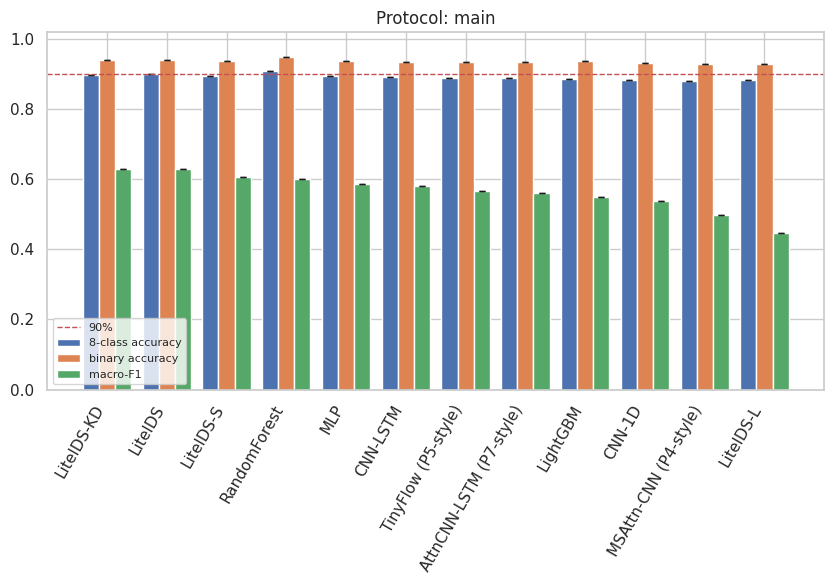

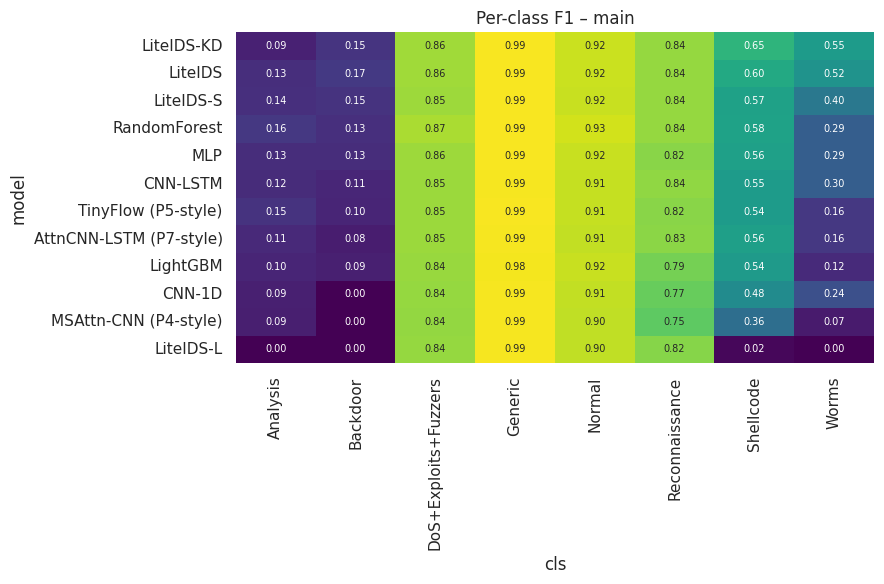

precision  recall      f1  support
protocol cls                                                     
main     Analysis                 0.4493  0.0773  0.1319    401.0
         Backdoor                 0.6471  0.0946  0.1650    349.0
         DoS+Exploits+Fuzzers     0.8497  0.8673  0.8584  12769.0
         Generic                  0.9959  0.9837  0.9897   8831.0
         Normal                   0.9047  0.9378  0.9209  13950.0
         Reconnaissance           0.8848  0.8051  0.8430   2098.0
         Shellcode                0.4904  0.7885  0.6047    227.0
         Worms                    0.4250  0.6538  0.5152     26.0

In [10]:
MEAN = RES.groupby(['protocol', 'model'])[MET].mean(); STD = RES.groupby(['protocol', 'model'])[MET].std().fillna(0)
order = lambda prot: MEAN.loc[prot].sort_values('macro_f1', ascending=False).index.tolist()
fig, axes = plt.subplots(1, len(PROTOCOLS), figsize=(8.5 * len(PROTOCOLS), 6), squeeze=False)
for ax, prot in zip(axes[0], PROTOCOLS):
    od = order(prot); x = np.arange(len(od)); wd = .27
    for j, (m, lab) in enumerate([('accuracy', '8-class accuracy'), ('binary_accuracy', 'binary accuracy'), ('macro_f1', 'macro-F1')]):
        ax.bar(x + (j - 1) * wd, MEAN.loc[prot].loc[od, m], wd, yerr=STD.loc[prot].loc[od, m], label=lab, capsize=2)
    ax.axhline(.9, color='r', ls='--', lw=1, label='90%'); ax.set_xticks(x); ax.set_xticklabels(od, rotation=60, ha='right')
    ax.set_ylim(0, 1.02); ax.set_title(f'Protocol: {prot}'); ax.legend(loc='lower left', fontsize=8)
savefig('fig02_model_comparison')

fig, axes = plt.subplots(1, len(PROTOCOLS), figsize=(9 * len(PROTOCOLS), 6), squeeze=False)
for ax, prot in zip(axes[0], PROTOCOLS):
    hm = PC[PC.protocol == prot].groupby(['model', 'cls']).f1.mean().unstack()[CLASSES].loc[order(prot)]
    sns.heatmap(hm, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, ax=ax, cbar=False, annot_kws={'size': 7}); ax.set_title(f'Per-class F1 – {prot}')
savefig('fig03_per_class_f1_heatmap')
tab = PC[PC.model == 'LiteIDS'].groupby(['protocol', 'cls'])[['precision', 'recall', 'f1', 'support']].mean().round(4)
savetab(tab, 'table_per_class_LiteIDS'); display(tab)

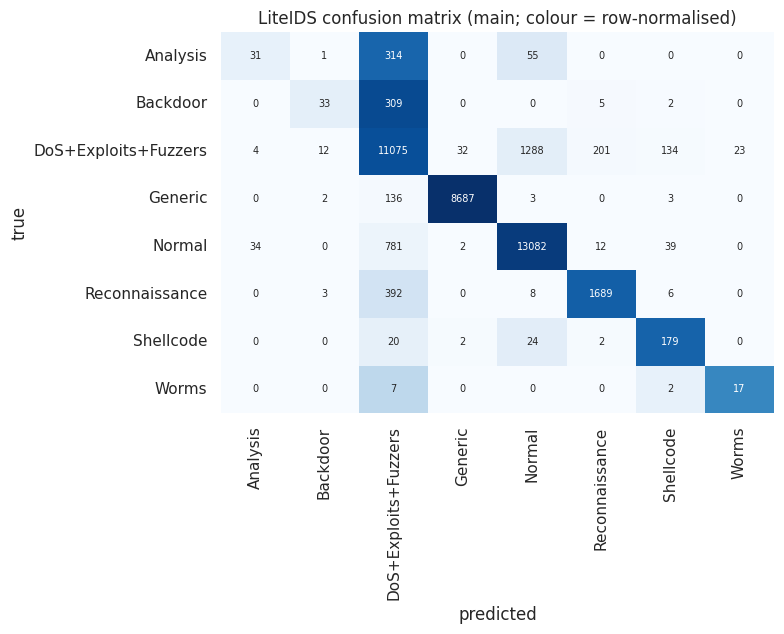

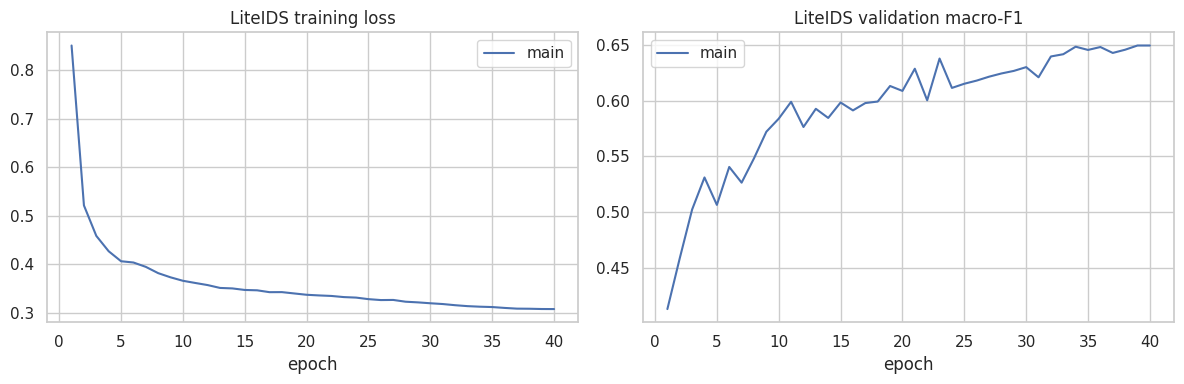

In [11]:
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, len(PROTOCOLS), figsize=(8 * len(PROTOCOLS), 6.5), squeeze=False)
for ax, prot in zip(axes[0], PROTOCOLS):
    nm = 'LiteIDS' if ('LiteIDS' in set(RES.model)) else 'LightGBM'
    cm = confusion_matrix(YTRUE[prot], PRED[(prot, nm)], labels=range(C)); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    sns.heatmap(cmn, annot=cm, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False, annot_kws={'size': 7})
    ax.set_title(f'{nm} confusion matrix ({prot}; colour = row-normalised)'); ax.set_xlabel('predicted'); ax.set_ylabel('true')
savefig('fig04_confusion_matrix')

if USE_NN:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for prot in PROTOCOLS:
        h = pd.DataFrame(HIST[(prot, 'LiteIDS')])
        axes[0].plot(h.epoch, h.train_loss, label=prot); axes[1].plot(h.epoch, h.val_macro_f1, label=prot)
    axes[0].set_title('LiteIDS training loss'); axes[1].set_title('LiteIDS validation macro-F1')
    for a in axes: a.set_xlabel('epoch'); a.legend()
    savefig('fig05_training_curves')

In [12]:
# ---- E2: efficiency profile of every model (CPU, 1 thread, batch size 1) ----
prof = []
for (prot, name), m in STORE.items():
    D = get_protocol(prot, SEEDS[0])
    row = profile_nn(m, D, 100 if QUICK else 300) if isinstance(m, nn.Module) else profile_sklearn(m, D, 50 if QUICK else 200)
    prof.append(dict(protocol=prot, model=name, **row)); print(prot, name, {k: round(v, 3) if isinstance(v, float) else v for k, v in row.items()})
PROF = pd.DataFrame(prof); savetab(PROF, 'table_efficiency_profile', index=False)
print('Hardware for all latency numbers:', HW, '| CPU-only, 1 thread, batch size 1. Tree models: params = total tree nodes.')

cost = RES.groupby(['protocol', 'model'])[['train_time_s', 'epochs_to_best', 'time_per_epoch_s', 'peak_train_mem_mb']].agg(['mean', 'std'])
savetab(cost, 'table_training_cost')
card = MEAN[['accuracy', 'binary_accuracy', 'macro_f1', 'mcc', 'false_alarm_rate']].join(PROF.set_index(['protocol', 'model'])).join(
    RES.groupby(['protocol', 'model'])[['train_time_s', 'epochs_to_best', 'peak_train_mem_mb']].mean())
savetab(card.round(4), 'report_card')
for prot in PROTOCOLS:
    print(f'\n##### REPORT CARD – {prot} #####'); display(card.loc[prot].sort_values('macro_f1', ascending=False).round(4))

main RandomForest {'params': 2282394, 'flops': nan, 'size_mb': 292.191, 'lat_mean_ms': np.float64(6.138), 'lat_p95_ms': np.float64(7.694), 'lat_p99_ms': np.float64(11.876), 'throughput_sps': 40100.514, 'infer_rss_delta_mb': nan}
main LightGBM {'params': 300000, 'flops': nan, 'size_mb': 16.641, 'lat_mean_ms': np.float64(1.539), 'lat_p95_ms': np.float64(2.436), 'lat_p99_ms': np.float64(3.785), 'throughput_sps': 2559.087, 'infer_rss_delta_mb': nan}
main LiteIDS-S {'params': 16976, 'flops': 942720, 'size_mb': 0.077, 'lat_mean_ms': np.float64(1.218), 'lat_p95_ms': np.float64(1.459), 'lat_p99_ms': np.float64(2.102), 'infer_rss_delta_mb': 15.966, 'throughput_sps': 11543.619}
main LiteIDS {'params': 86952, 'flops': 6592000, 'size_mb': 0.362, 'lat_mean_ms': np.float64(1.485), 'lat_p95_ms': np.float64(1.779), 'lat_p99_ms': np.float64(2.443), 'infer_rss_delta_mb': 45.785, 'throughput_sps': 3160.357}
main LiteIDS-L {'params': 453992, 'flops': 36707840, 'size_mb': 1.836, 'lat_mean_ms': np.float64(2

,accuracy,binary_accuracy,macro_f1,mcc,false_alarm_rate,params,flops,size_mb,lat_mean_ms,lat_p95_ms,lat_p99_ms,throughput_sps,infer_rss_delta_mb,train_time_s,epochs_to_best,peak_train_mem_mb
model,,,,,,,,,,,,,,,,
LiteIDS-KD,0.8995,0.9400,0.6302,0.8562,0.0695,86952,6592000.0,0.3622,1.9366,2.3492,3.5754,2453.4045,0.0000,315.1214,32.0,512.0415
LiteIDS,0.9002,0.9419,0.6286,0.8575,0.0622,86952,6592000.0,0.3622,1.4854,1.7786,2.4432,3160.3567,45.7851,180.1388,35.0,501.1374
LiteIDS-S,0.8964,0.9388,0.6068,0.8520,0.0694,16976,942720.0,0.0768,1.2184,1.4594,2.1023,11543.6187,15.9662,67.0149,35.0,283.7847
RandomForest,0.9093,0.9495,0.6001,0.8705,0.0647,2282394,NaN,292.1911,6.1383,7.6939,11.8759,40100.5141,NaN,63.2636,NaN,NaN
MLP,0.8961,0.9395,0.5871,0.8516,0.0719,47868,93696.0,0.1954,0.2737,0.4353,0.7667,611381.6090,0.0000,27.2236,35.0,77.7677
CNN-LSTM,0.8923,0.9363,0.5823,0.8462,0.0776,26364,10816.0,0.1099,0.6216,0.7693,1.0907,37948.7297,0.0492,39.4825,38.0,186.1253
TinyFlow (P5-style),0.8909,0.9359,0.5666,0.8444,0.0846,18020,998688.0,0.0829,1.8485,2.6374,3.6548,7746.7178,0.2048,93.1548,34.0,240.2468
AttnCNN-LSTM (P7-style),0.8904,0.9352,0.5613,0.8437,0.0909,26429,14016.0,0.1106,0.8768,1.0194,1.1968,22758.9004,0.0000,44.9947,35.0,186.6184
LightGBM,0.8860,0.9383,0.5484,0.8374,0.0715,300000,NaN,16.6409,1.5392,2.4356,3.7848,2559.0871,NaN,96.5875,NaN,NaN


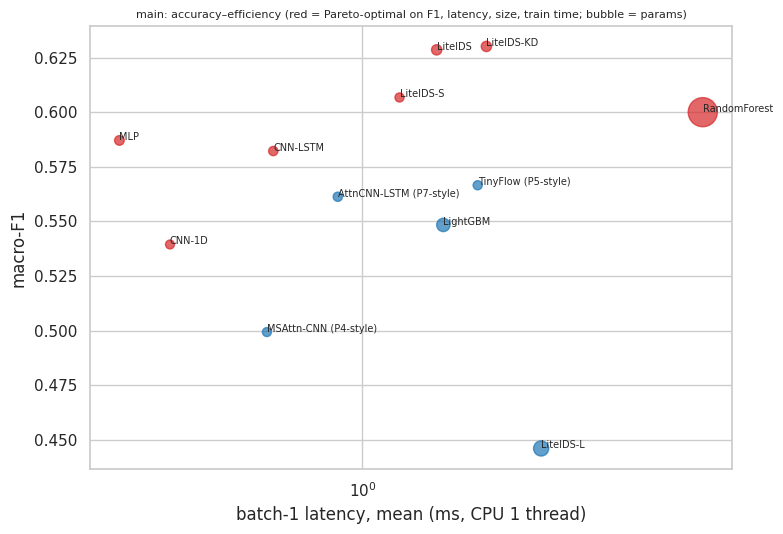

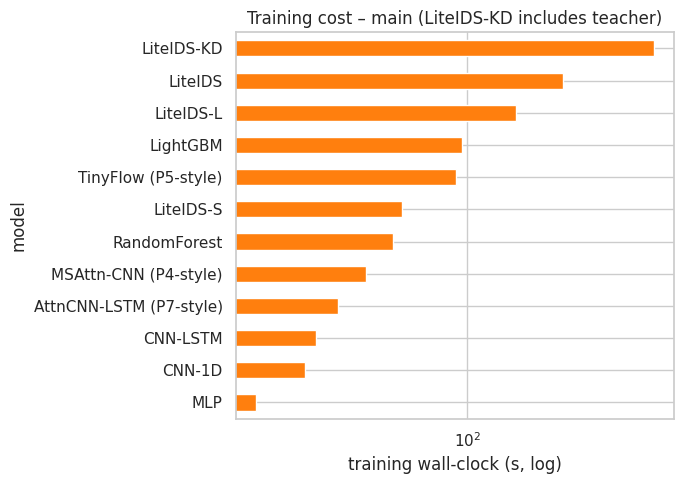

In [13]:
# ---- Pareto view + training-cost figure ----
def pareto(df, maximise, minimise):
    keep = []
    for i, r in df.iterrows():
        dom = False
        for j, o in df.iterrows():
            if i == j: continue
            ge = all(o[c] >= r[c] for c in maximise) and all(o[c] <= r[c] for c in minimise)
            gt = any(o[c] > r[c] for c in maximise) or any(o[c] < r[c] for c in minimise)
            if ge and gt: dom = True; break
        keep.append(not dom)
    return df[keep].index.tolist()

fig, axes = plt.subplots(1, len(PROTOCOLS), figsize=(8 * len(PROTOCOLS), 5.5), squeeze=False)
for ax, prot in zip(axes[0], PROTOCOLS):
    d = card.loc[prot].dropna(subset=['lat_mean_ms']).copy()
    front = pareto(d, ['macro_f1'], ['lat_mean_ms', 'params', 'train_time_s'])
    ax.scatter(d.lat_mean_ms, d.macro_f1, s=40 + 400 * d.params / d.params.max(), c=['tab:red' if i in front else 'tab:blue' for i in d.index], alpha=.7)
    for i, r in d.iterrows(): ax.annotate(i, (r.lat_mean_ms, r.macro_f1), fontsize=7)
    ax.set_xscale('log'); ax.set_xlabel('batch-1 latency, mean (ms, CPU 1 thread)'); ax.set_ylabel('macro-F1')
    ax.set_title(f'{prot}: accuracy–efficiency (red = Pareto-optimal on F1, latency, size, train time; bubble = params)')
    ax.title.set_fontsize(8)
savefig('fig06_pareto')

fig, axes = plt.subplots(1, len(PROTOCOLS), figsize=(7 * len(PROTOCOLS), 5), squeeze=False)
for ax, prot in zip(axes[0], PROTOCOLS):
    c = RES[RES.protocol == prot].groupby('model').train_time_s.mean().sort_values()
    c.plot.barh(ax=ax, color='tab:orange'); ax.set_xscale('log'); ax.set_xlabel('training wall-clock (s, log)'); ax.set_title(f'Training cost – {prot} (LiteIDS-KD includes teacher)')
savefig('fig07_training_cost')

## 8. Ablation studies (E5, E6)
Run with `ABL_SEEDS` on the same split as the main experiment. Components removed / replaced / varied: attention (→ token-mixing layer of the same position), heads, blocks, width, SE gating, loss function, class-weighting strength, training-only oversampling, mutual-information feature selection (top-30 numeric features) and direct vs teacher–student training. Accuracy is reported **together with** parameters, FLOPs and training time.

Full LiteIDS (d64, 2 blocks, 4 heads, SE)                  seed=0 acc=0.9002 bin=0.9419 F1=0.6286
Attention -> token-mixing layer                            seed=0 acc=0.8998 bin=0.9420 F1=0.6256
Heads = 1                                                  seed=0 acc=0.9001 bin=0.9418 F1=0.6286
Heads = 2                                                  seed=0 acc=0.9002 bin=0.9418 F1=0.6336
Heads = 8                                                  seed=0 acc=0.9022 bin=0.9432 F1=0.6350
Blocks = 1                                                 seed=0 acc=0.8983 bin=0.9403 F1=0.6252
Blocks = 3                                                 seed=0 acc=0.9005 bin=0.9424 F1=0.6252
Width = 16                                                 seed=0 acc=0.8902 bin=0.9360 F1=0.5860
Width = 32                                                 seed=0 acc=0.8971 bin=0.9396 F1=0.6255
Width = 128                                                seed=0 acc=0.8989 bin=0.9411 F1=0.6359
No SE gating        

,params,flops,train_s,acc,bin_acc,macro_f1,macro_f1_std,mcc
config,,,,,,,,
"Full LiteIDS (d64, 2 blocks, 4 heads, SE)",86952,6592000.0,180.1770,0.9002,0.9419,0.6286,NaN,0.8575
Attention -> token-mixing layer,57456,3300608.0,106.9227,0.8998,0.9420,0.6256,NaN,0.8569
Heads = 1,86952,6592000.0,144.0741,0.9001,0.9418,0.6286,NaN,0.8574
Heads = 2,86952,6592000.0,160.1171,0.9002,0.9418,0.6336,NaN,0.8575
Heads = 8,86952,6592000.0,232.0736,0.9022,0.9432,0.6350,NaN,0.8604
Blocks = 1,51352,3296512.0,95.5877,0.8983,0.9403,0.6252,NaN,0.8547
Blocks = 3,122552,9887488.0,263.1835,0.9005,0.9424,0.6252,NaN,0.8580
Width = 16,8688,589696.0,68.7622,0.8902,0.9360,0.5860,NaN,0.8433
Width = 32,26072,1884928.0,112.8867,0.8971,0.9396,0.6255,NaN,0.8530


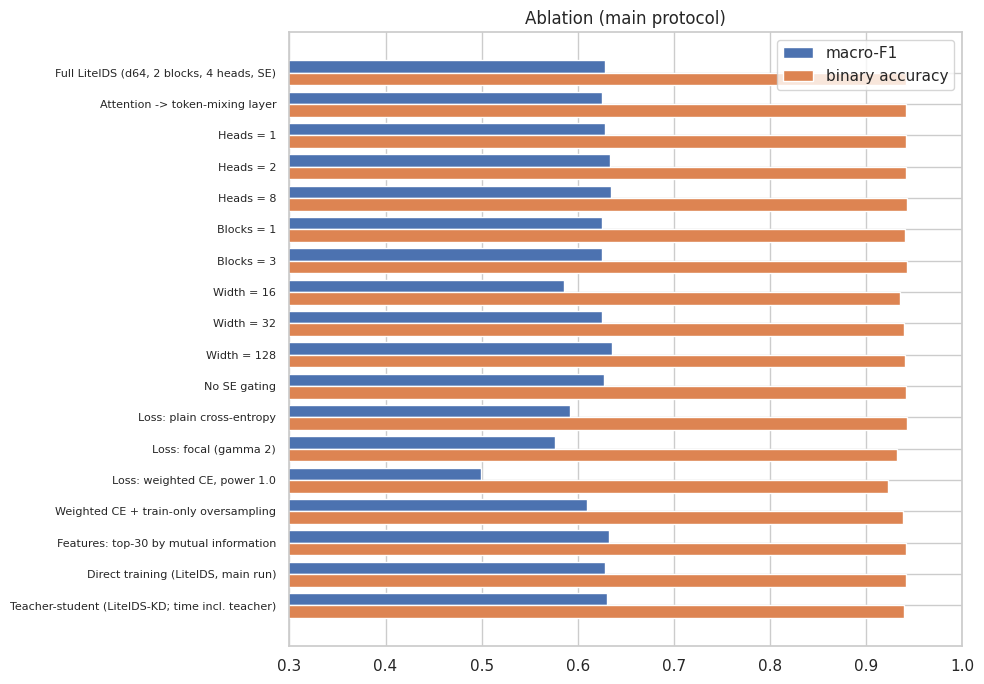

In [14]:
ABL_PROT = PROTOCOLS[0]
BASE = dict(d=64, h=4, L=2, ff=2, se=True, mix=False)

def select_features(D, k):
    if D['n_num'] <= k: return D
    idx = np.random.RandomState(0).choice(len(D['train'][2]), min(20000, len(D['train'][2])), replace=False)
    mi = mutual_info_classif(D['train'][0][idx], D['train'][2][idx], random_state=0)
    keep = np.sort(np.argsort(mi)[::-1][:k]); D2 = dict(D)
    for s in ('train', 'val', 'test'): D2[s] = (D[s][0][:, keep], D[s][1], D[s][2])
    D2['n_num'] = k; D2['num_cols'] = [D['num_cols'][i] for i in keep]; build_tensors(D2); return D2

ABL = [('Full LiteIDS (d64, 2 blocks, 4 heads, SE)', {}, {}, None),
       ('Attention -> token-mixing layer', dict(mix=True), {}, None),
       ('Heads = 1', dict(h=1), {}, None), ('Heads = 2', dict(h=2), {}, None), ('Heads = 8', dict(h=8), {}, None),
       ('Blocks = 1', dict(L=1), {}, None), ('Blocks = 3', dict(L=3), {}, None),
       ('Width = 16', dict(d=16, h=2), {}, None), ('Width = 32', dict(d=32, h=2), {}, None), ('Width = 128', dict(d=128), {}, None),
       ('No SE gating', dict(se=False), {}, None),
       ('Loss: plain cross-entropy', {}, dict(loss='ce'), None), ('Loss: focal (gamma 2)', {}, dict(loss='focal'), None),
       ('Loss: weighted CE, power 1.0', {}, dict(power=1.0), None),
       ('Weighted CE + train-only oversampling', {}, dict(oversample=True), None),
       ('Features: top-30 by mutual information', {}, {}, 30)]
if QUICK: ABL = ABL[:4]
arows = []
for name, mk, tk, fk in ABL:
    for seed in ABL_SEEDS:
        D = get_protocol(ABL_PROT, seed)
        if fk: D = select_features(D, fk)
        model, _, cost = train_model(lambda D_, mk=mk: LiteIDS(D_['n_num'], D_['vocab'], C, **{**BASE, **mk}), D, seed, **{**WCE, **tk})
        m, _ = metrics(D['test'][2], predict_proba(model, *D['t']['test'][:2])); eff = profile_nn(model, D, full=False)
        arows.append(dict(config=name, seed=seed, params=eff['params'], flops=eff['flops'], train_time_s=cost['train_time_s'],
                          **{k: m[k] for k in ('accuracy', 'binary_accuracy', 'macro_f1', 'mcc')}))
        print(f'{name:58s} seed={seed} acc={m["accuracy"]:.4f} bin={m["binary_accuracy"]:.4f} F1={m["macro_f1"]:.4f}')
        del model
    if DEV == 'cuda': torch.cuda.empty_cache()
for lab, nm in (('Direct training (LiteIDS, main run)', 'LiteIDS'), ('Teacher-student (LiteIDS-KD; time incl. teacher)', 'LiteIDS-KD')):
    npar = PROF[(PROF.protocol == ABL_PROT) & (PROF.model == nm)].params
    for _, x in RES[(RES.protocol == ABL_PROT) & (RES.model == nm)].iterrows():
        arows.append(dict(config=lab, seed=x.seed, params=npar.iloc[0] if len(npar) else np.nan, flops=np.nan, train_time_s=x.train_time_s,
                          accuracy=x.accuracy, binary_accuracy=x.binary_accuracy, macro_f1=x.macro_f1, mcc=x.mcc))
ABLDF = pd.DataFrame(arows)
abl_tab = ABLDF.groupby('config', sort=False).agg(params=('params', 'first'), flops=('flops', 'first'), train_s=('train_time_s', 'mean'),
        acc=('accuracy', 'mean'), bin_acc=('binary_accuracy', 'mean'), macro_f1=('macro_f1', 'mean'), macro_f1_std=('macro_f1', 'std'), mcc=('mcc', 'mean')).round(4)
savetab(abl_tab, 'table_ablation'); display(abl_tab)

d = ABLDF.groupby('config', sort=False)[['macro_f1', 'binary_accuracy']].agg(['mean', 'std']).fillna(0)
fig, ax = plt.subplots(figsize=(10, 7)); y = np.arange(len(d))
ax.barh(y - .2, d['macro_f1']['mean'], .4, xerr=d['macro_f1']['std'], label='macro-F1'); ax.barh(y + .2, d['binary_accuracy']['mean'], .4, xerr=d['binary_accuracy']['std'], label='binary accuracy')
ax.set_yticks(y); ax.set_yticklabels(d.index, fontsize=8); ax.invert_yaxis(); ax.set_xlim(.3, 1); ax.legend(); ax.set_title(f'Ablation ({ABL_PROT} protocol)')
savefig('fig08_ablation')

## 9. Comparison with existing research
Literature numbers are **as reported in the Phase 2 review** and were **not re-measured**. Comparability is limited: split protocols, class handling (binary / 10-class / 8-class), feature sets, preprocessing and hardware differ between studies.

,method,dataset,split protocol,reported accuracy %,comparability note
0,MAFD-Net (P1),UNSW-NB15,as reported,78.32,Image conversion + B7 teacher
1,MA-1D-CNN (P4),UNSW-NB15 (9 shared features),as reported,99.37,98.64 in its own ablation table; desktop GPU
2,Fed. Attn-LSTM + LLM (P10),UNSW-NB15,binary Normal vs Attack,98.05,Binary task; LLM modules excluded from cost
3,HED-ID cloud-like (P11),UNSW-NB15,"stratified 70/15/15, windows",95.60,Simulated edge; no params/FLOPs
4,HED-ID edge-like (P11),UNSW-NB15,"stratified 70/15/15, windows",93.80,Simulated edge; no params/FLOPs
5,"LiteIDS (ours, main, 8-class)",UNSW-NB15,"stratified 70/15/15, all records",90.02,this work; mean over seeds
6,"LiteIDS (ours, main, binary)",UNSW-NB15,"stratified 70/15/15, all records",94.19,this work; mean over seeds


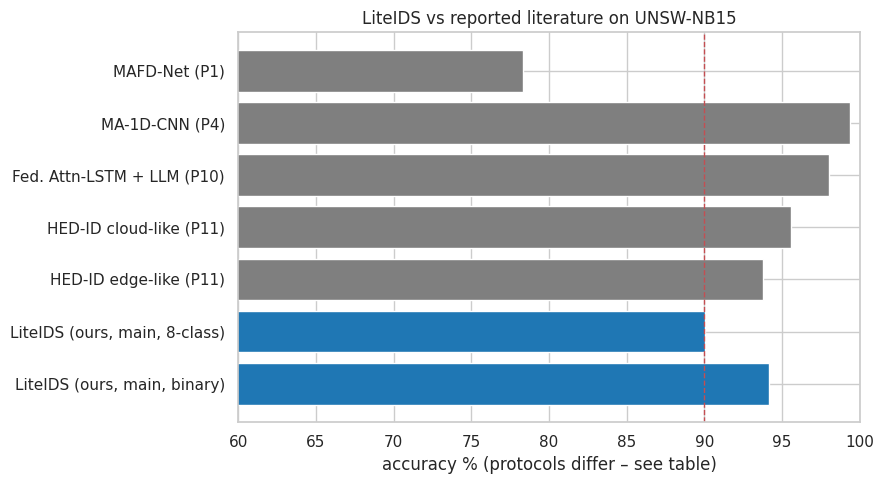

In [15]:
def ours(prot, name, col):
    r = MEAN.loc[(prot, name)] if (prot, name) in MEAN.index else None
    return None if r is None else 100 * r[col]
main = 'LiteIDS' if USE_NN else 'LightGBM'
LIT = pd.DataFrame([
 ['MAFD-Net (P1)', 'UNSW-NB15', 'as reported', 78.32, 'Image conversion + B7 teacher'],
 ['MA-1D-CNN (P4)', 'UNSW-NB15 (9 shared features)', 'as reported', 99.37, '98.64 in its own ablation table; desktop GPU'],
 ['Fed. Attn-LSTM + LLM (P10)', 'UNSW-NB15', 'binary Normal vs Attack', 98.05, 'Binary task; LLM modules excluded from cost'],
 ['HED-ID cloud-like (P11)', 'UNSW-NB15', 'stratified 70/15/15, windows', 95.6, 'Simulated edge; no params/FLOPs'],
 ['HED-ID edge-like (P11)', 'UNSW-NB15', 'stratified 70/15/15, windows', 93.8, 'Simulated edge; no params/FLOPs']],
 columns=['method', 'dataset', 'split protocol', 'reported accuracy %', 'comparability note'])
rows = []
for prot in PROTOCOLS:
    for col, lab in (('accuracy', '8-class'), ('binary_accuracy', 'binary')):
        v = ours(prot, main, col)
        if v is not None: rows.append([f'{main} (ours, {prot}, {lab})', 'UNSW-NB15', 'stratified 70/15/15, all records', round(v, 2), 'this work; mean over seeds'])
CMP = pd.concat([LIT, pd.DataFrame(rows, columns=LIT.columns)], ignore_index=True)
savetab(CMP, 'table_literature_comparison', index=False); display(CMP)
fig, ax = plt.subplots(figsize=(9, 5)); cols = ['tab:blue' if 'ours' in m else 'tab:gray' for m in CMP.method]
ax.barh(CMP.method, CMP['reported accuracy %'], color=cols); ax.axvline(90, color='r', ls='--', lw=1); ax.set_xlim(60, 100); ax.invert_yaxis()
ax.set_xlabel('accuracy % (protocols differ – see table)'); ax.set_title('LiteIDS vs reported literature on UNSW-NB15')
savefig('fig09_literature_comparison')

## 10. Statistical analysis

In [16]:
def holm(p):
    p = np.array(p, float); o = np.argsort(p); adj = np.empty_like(p); run = 0.
    for r, i in enumerate(o): run = max(run, (len(p) - r) * p[i]); adj[i] = min(run, 1.)
    return adj
def mcnemar(y, pa, pb):
    ca, cb = pa == y, pb == y; b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
    return 1. if b + c == 0 else stats.binomtest(min(b, c), b + c, .5).pvalue
if len(SEEDS) < 6: print(f'NOTE: only {len(SEEDS)} seeds -> Wilcoxon p-values cannot go below {2/2**len(SEEDS):.3f}; rely on effect sizes. Use >=6 (ideally 10) seeds.')
srows = []
for prot in PROTOCOLS:
    base = RES[(RES.protocol == prot) & (RES.model == main)].sort_values('seed')
    others = [m for m in RES.model.unique() if m != main]; ps = []; tmp = []
    for m in others:
        o = RES[(RES.protocol == prot) & (RES.model == m)].sort_values('seed'); diff = base.macro_f1.values - o.macro_f1.values
        try: p = stats.wilcoxon(base.macro_f1.values, o.macro_f1.values).pvalue if len(diff) > 1 else np.nan
        except ValueError: p = np.nan
        dz = diff.mean() / diff.std(ddof=1) if len(diff) > 1 and diff.std(ddof=1) > 0 else np.nan
        mc = mcnemar(YTRUE[prot], PRED[(prot, main)], PRED[(prot, m)]) if (prot, m) in PRED else np.nan
        tmp.append([prot, m, diff.mean(), dz, p, mc])
    adj = holm([t[4] if not np.isnan(t[4]) else 1. for t in tmp])
    srows += [t + [a] for t, a in zip(tmp, adj)]
STAT = pd.DataFrame(srows, columns=['protocol', f'vs ({main})', 'mean macro-F1 diff', 'paired effect size dz', 'Wilcoxon p', 'McNemar p (seed 0, accuracy)', 'Holm-adj. Wilcoxon p'])
savetab(STAT.round(4), 'table_statistical_tests', index=False); display(STAT.round(4))

# 95% bootstrap CIs of per-class F1 for the main model (test set, seed 0)
def boot_f1(y, p, B=300, seed=0):
    rng = np.random.default_rng(seed); n = len(y); out = np.zeros((B, C))
    for b in range(B):
        i = rng.integers(0, n, n); yy, pp = y[i], p[i]
        tp = np.bincount(yy[yy == pp], minlength=C); fp = np.bincount(pp, minlength=C) - tp; fn = np.bincount(yy, minlength=C) - tp
        out[b] = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    return np.percentile(out, [2.5, 97.5], axis=0)
ci_rows = []
for prot in PROTOCOLS:
    lo, hi = boot_f1(YTRUE[prot], PRED[(prot, main)]); t = PC[(PC.protocol == prot) & (PC.model == main) & (PC.seed == SEEDS[0])].set_index('cls')
    for c in range(C): ci_rows.append(dict(protocol=prot, cls=CLASSES[c], support=int(t.loc[CLASSES[c], 'support']), f1=t.loc[CLASSES[c], 'f1'], ci_low=lo[c], ci_high=hi[c]))
CI = pd.DataFrame(ci_rows); savetab(CI.round(4), 'table_per_class_f1_bootstrap_ci', index=False); display(CI.round(3))

NOTE: only 1 seeds -> Wilcoxon p-values cannot go below 1.000; rely on effect sizes. Use >=6 (ideally 10) seeds.


,protocol,vs (LiteIDS),mean macro-F1 diff,paired effect size dz,Wilcoxon p,"McNemar p (seed 0, accuracy)",Holm-adj. Wilcoxon p
0,main,RandomForest,0.0286,NaN,NaN,0.0000,1.0
1,main,LightGBM,0.0802,NaN,NaN,0.0000,1.0
2,main,LiteIDS-S,0.0218,NaN,NaN,0.0000,1.0
3,main,LiteIDS-L,0.1826,NaN,NaN,0.0000,1.0
4,main,MLP,0.0415,NaN,NaN,0.0000,1.0
5,main,CNN-1D,0.0892,NaN,NaN,0.0000,1.0
6,main,CNN-LSTM,0.0464,NaN,NaN,0.0000,1.0
7,main,MSAttn-CNN (P4-style),0.1293,NaN,NaN,0.0000,1.0
8,main,TinyFlow (P5-style),0.0620,NaN,NaN,0.0000,1.0
9,main,AttnCNN-LSTM (P7-style),0.0673,NaN,NaN,0.0000,1.0


,protocol,cls,support,f1,ci_low,ci_high
0,main,Analysis,401,0.132,0.088,0.176
1,main,Backdoor,349,0.165,0.122,0.211
2,main,DoS+Exploits+Fuzzers,12769,0.858,0.854,0.863
3,main,Generic,8831,0.990,0.988,0.991
4,main,Normal,13950,0.921,0.918,0.924
5,main,Reconnaissance,2098,0.843,0.831,0.854
6,main,Shellcode,227,0.605,0.557,0.655
7,main,Worms,26,0.515,0.375,0.658


## 11. Error and failure analysis
Confusion structure (Fig. 4), decision-threshold / false-alarm behaviour, calibration (ECE), attention weights as a *diagnostic only*,

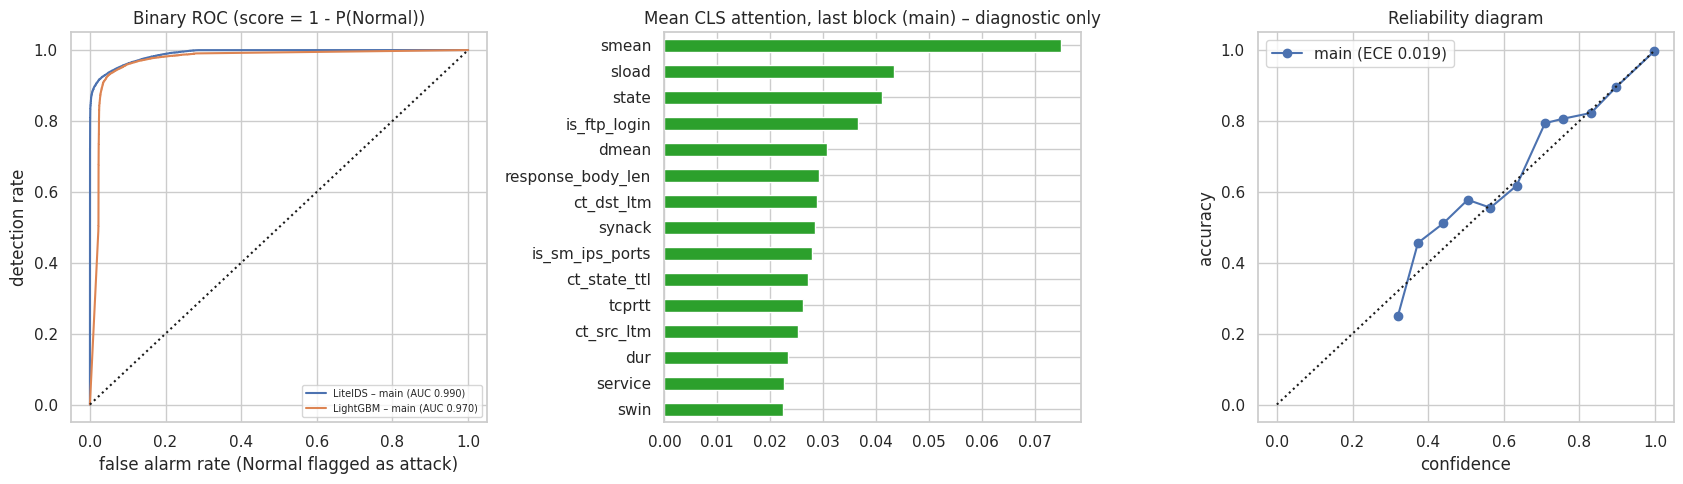

ECE: {'main': np.float64(0.0189)}

Top confusions (main):
  DoS+Exploits+Fuzzers -> Normal          1288
  Normal          -> DoS+Exploits+Fuzzers 781
  Reconnaissance  -> DoS+Exploits+Fuzzers 392
  Analysis        -> DoS+Exploits+Fuzzers 314
  Backdoor        -> DoS+Exploits+Fuzzers 309


In [17]:
def ece(prob, y, bins=15):
    conf, pred = prob.max(1), prob.argmax(1); edges = np.linspace(0, 1, bins + 1); e = 0.; pts = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean()); pts.append((conf[m].mean(), (pred[m] == y[m]).mean()))
    return e, np.array(pts)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ecs = {}
for prot in PROTOCOLS:
    for nm in (main, 'LightGBM'):
        score = 1 - PROB[(prot, nm)][:, NORMAL]; yb = YTRUE[prot] != NORMAL
        fpr, tpr, _ = roc_curve(yb, score); axes[0].plot(fpr, tpr, label=f'{nm} – {prot} (AUC {roc_auc_score(yb, score):.3f})')
    e, pts = ece(PROB[(prot, main)], YTRUE[prot]); ecs[prot] = e
    axes[2].plot(pts[:, 0], pts[:, 1], 'o-', label=f'{prot} (ECE {e:.3f})')
axes[0].plot([0, 1], [0, 1], 'k:'); axes[0].set_xlabel('false alarm rate (Normal flagged as attack)'); axes[0].set_ylabel('detection rate'); axes[0].set_title('Binary ROC (score = 1 - P(Normal))'); axes[0].legend(fontsize=7)
axes[2].plot([0, 1], [0, 1], 'k:'); axes[2].set_xlabel('confidence'); axes[2].set_ylabel('accuracy'); axes[2].set_title('Reliability diagram'); axes[2].legend()
if USE_NN:
    prot = PROTOCOLS[-1]; D = get_protocol(prot, SEEDS[0]); m = STORE[(prot, 'LiteIDS')].to(DEV).eval(); xn, xc, _y = D['t']['test']; sel = torch.arange(min(3000, len(_y)), device=DEV)
    with torch.no_grad(): _, att = m(xn[sel], xc[sel], ret=True)
    a = att[-1][:, :, 0, :].mean((0, 1)).cpu().numpy(); names = ['[CLS]'] + D['num_cols'] + CAT_COLS; STORE[(prot, 'LiteIDS')] = m.cpu()
    top = pd.Series(a, names).drop('[CLS]').sort_values(ascending=False).head(15)
    top.iloc[::-1].plot.barh(ax=axes[1], color='tab:green'); axes[1].set_title(f'Mean CLS attention, last block ({prot}) – diagnostic only')
else: axes[1].axis('off')
savefig('fig10_error_analysis')
print('ECE:', {k: round(v, 4) for k, v in ecs.items()})
for prot in PROTOCOLS:
    cm = confusion_matrix(YTRUE[prot], PRED[(prot, main)], labels=range(C)); off = cm.copy(); np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
    print(f'\nTop confusions ({prot}):'); [print(f'  {CLASSES[i]:15s} -> {CLASSES[j]:15s} {off[i, j]}') for i, j in top]

## 12. Results summary, the 90% check, and discussion

In [18]:
summary = {}
for prot in PROTOCOLS:
    best = MEAN.loc[prot].sort_values('macro_f1', ascending=False).index[0]; r = MEAN.loc[(prot, main)]
    summary[prot] = dict(main_model=main, accuracy_10class=r.accuracy, accuracy_binary=r.binary_accuracy, macro_f1=r.macro_f1, mcc=r.mcc,
                         best_macro_f1_model=best, best_binary_acc_model=MEAN.loc[prot].binary_accuracy.idxmax(), best_binary_acc=MEAN.loc[prot].binary_accuracy.max())
    print(f'[{prot}] {main}: 8-class acc {r.accuracy:.4f} | attack-vs-normal acc {r.binary_accuracy:.4f} | macro-F1 {r.macro_f1:.4f} | MCC {r.mcc:.4f}')
    print(f'        >=90% binary accuracy: {"YES" if r.binary_accuracy >= .9 else "NO"} | >=90% 8-class accuracy: {"YES" if r.accuracy >= .9 else "NO"}')
    print(f'        best macro-F1 model: {best} | best binary accuracy: {summary[prot]["best_binary_acc_model"]} ({summary[prot]["best_binary_acc"]:.4f})')
json.dump(dict(summary=summary, hardware=HW), open(OUT/'results_summary.json', 'w'), indent=2, default=float)

[main] LiteIDS: 8-class acc 0.9002 | attack-vs-normal acc 0.9419 | macro-F1 0.6286 | MCC 0.8575
        >=90% binary accuracy: YES | >=90% 8-class accuracy: YES
        best macro-F1 model: LiteIDS-KD | best binary accuracy: RandomForest (0.9495)


### 12.1 Interpretation guide (complete after reading your own tables)
Use the printed numbers and the figures above to answer, in your report:
* **Does LiteIDS fill the gap?** Compare `report_card.csv` rows for LiteIDS vs the literature-style models: parameters, FLOPs, size, p95/p99 latency, training time **and** per-class F1 – the three groups of metrics Phase 2 committed to.
* **Is attention worth its cost?** Read `table_ablation.csv`: attention → token-mixing, heads, blocks, width, SE. Report the accuracy change *together with* params / FLOPs / time.
* **Where does it fail?** Rare classes (Worms, Shellcode, Backdoor, Analysis) – see `table_per_class_f1_bootstrap_ci.csv` (wide CIs reflect tiny support) and the top confusions.
* **Duplicates:** the setup table shows the share of test rows with an exact copy in the training set; discuss this as a limitation (scores are optimistic relative to a duplicate-free split).
* **Direct vs teacher–student:** compare `LiteIDS` and `LiteIDS-KD` accuracy against total training time (teacher included).
* **Strengths / limitations:** single dataset, benchmark age, duplicate records retained in the split, re-implemented baselines, CPU proxy hardware, software-estimated FLOPs, few seeds, tiny rare-class test support.

### 12.2 Reproducibility
Seeds, library versions, hardware and all hyper-parameters are written to `config.json` in the results folder; raw per-seed results to `tables/raw_results.csv`.

In [19]:
# ---- write requirements, README and zip everything ----
import importlib.metadata as im
reqs = {p: im.version(p) for p in ('numpy', 'pandas', 'scikit-learn', 'scipy', 'lightgbm', 'matplotlib', 'seaborn', 'torch', 'joblib', 'psutil')}
(OUT/'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k, v in reqs.items()))
(OUT/'README.txt').write_text('''LiteIDS Phase 3 outputs
figures/  : fig01..fig10 PNG (dpi 200)
tables/   : CSV tables (main results, per-class, report card, efficiency, training cost, ablation, statistics, literature)
models/   : trained LiteIDS weights (seed 0)
config.json, results_summary.json, requirements.txt
''')
for (prot, name), m in STORE.items():
    if isinstance(m, nn.Module) and name.startswith('LiteIDS'): torch.save(m.state_dict(), MOD / f'{name}_{prot}_seed{SEEDS[0]}.pt')
# ---- final model package: <results folder>/final_model ----
FINAL = OUT / 'final_model'; FINAL.mkdir(exist_ok=True)
if USE_NN:
    D0 = get_protocol(PROTOCOLS[0], SEEDS[0]); pp = D0['prep']
    ARCH = {'LiteIDS': dict(d=64, h=4, L=2), 'LiteIDS-S': dict(d=32, h=2, L=1), 'LiteIDS-L': dict(d=128, h=4, L=3), 'LiteIDS-KD': dict(d=64, h=4, L=2)}
    for name, kw in ARCH.items():
        if (PROTOCOLS[0], name) in STORE:
            torch.save({'state_dict': STORE[(PROTOCOLS[0], name)].state_dict(), 'classes': CLASSES,
                        'arch': dict(n_num=D0['n_num'], vocab=D0['vocab'], n_cls=C, ff=2, se=True, mix=False, **kw)},
                       FINAL / ('liteids.pt' if name == 'LiteIDS' else f'{name.lower().replace("-", "_")}.pt'))
    json.dump(dict(num_cols=NUM_COLS, cat_cols=CAT_COLS, vocab=pp.vocab, log_cols=pp.log_cols,
                   mean=pp.mu.to_dict(), std=pp.sd.to_dict(), clip=10, classes=CLASSES, merge_map=MERGE8),
              open(FINAL / 'preprocessing.json', 'w'), indent=1)
    (FINAL / 'README.txt').write_text('''LiteIDS (Phase 3 final model)
liteids.pt          : main LiteIDS checkpoint {state_dict, arch, classes}  (other *.pt = size variants / distilled model)
preprocessing.json  : feature order, categorical vocabularies (0 = unseen), log1p columns, mean/std, clip value
Reload: define the LiteIDS class from the notebook, then
  ck = torch.load('liteids.pt'); m = LiteIDS(**ck['arch']); m.load_state_dict(ck['state_dict']); m.eval()
''')
    print('Final model saved to:', FINAL.resolve(), sorted(p.name for p in FINAL.iterdir()))
shutil.make_archive(str(OUT), 'zip', OUT)
print('All outputs saved in', OUT, '(and a zip beside it)'); print(sorted(p.name for p in FIG.glob('*.png')))

Final model saved to: /content/drive/MyDrive/LiteIDS_8Class_Phase3_Final_Results/final_model ['README.txt', 'liteids.pt', 'liteids_kd.pt', 'liteids_l.pt', 'liteids_s.pt', 'preprocessing.json']
All outputs saved in /content/drive/MyDrive/LiteIDS_8Class_Phase3_Final_Results (and a zip beside it)
['fig01_class_distribution.png', 'fig02_model_comparison.png', 'fig03_per_class_f1_heatmap.png', 'fig04_confusion_matrix.png', 'fig05_training_curves.png', 'fig06_pareto.png', 'fig07_training_cost.png', 'fig08_ablation.png', 'fig09_literature_comparison.png', 'fig10_error_analysis.png']
